In [ ]:
#importing the packages
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset, random_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, r2_score

# Set seed for reproducibility
torch.manual_seed(42)
np.random.seed(42)

cancer = pd.read_csv("/content/gradeddata.csv")
cancer.head()

,h1,h2,h3,l1,l2,l3,t1,t2,t3,tp1,...,r3,theta1,theta2,theta3,A1,A2,A3,MD (mm),RC(KN),SEA (J/Kg)
0,10.10,20.61,17.29,8.15,11.03,10.61,0.37,0.29,0.41,4.37,...,9.94,34.09,33.58,60.43,24.95,25.19,29.46,8.85,210.0,77.90
1,18.13,18.53,11.34,13.91,9.17,18.17,0.33,0.58,0.46,4.79,...,11.14,63.72,30.27,30.60,27.36,25.84,14.93,6.44,207.8,81.83
2,9.78,18.84,19.38,12.83,13.91,13.25,0.52,0.55,0.49,3.51,...,16.85,31.02,44.13,35.10,19.88,23.73,22.88,7.82,214.7,59.94
3,17.09,21.95,8.96,19.79,11.15,10.49,0.53,0.50,0.59,2.85,...,4.64,33.36,31.86,74.91,15.33,25.11,26.37,10.39,166.8,70.30
4,16.17,14.59,17.24,14.39,16.13,16.73,0.60,0.36,0.62,4.97,...,12.67,32.86,34.59,42.87,20.38,18.41,20.04,5.91,301.7,59.38


In [ ]:
# First 23 variables are input (indices 0 to 22)
X = cancer.iloc[:, :23].values

# Last 3 variables are output (index 23 to the end)
y = cancer.iloc[:, 23:].values

# Use numpy slicing [:5] to see the first 5 rows safely
print("Input (X) head (first 5 rows):")
print(X[:5])

print("\nOutput (y) head (first 5 rows):")
print(y[:5])

Input (X) head (first 5 rows):
[[10.1  20.61 17.29  8.15 11.03 10.61  0.37  0.29  0.41  4.37  2.89 19.88
  42.13 10.13  9.01 18.63  9.94 34.09 33.58 60.43 24.95 25.19 29.46]
 [18.13 18.53 11.34 13.91  9.17 18.17  0.33  0.58  0.46  4.79  3.93 48.38
  25.88 12.13 10.11 18.38 11.14 63.72 30.27 30.6  27.36 25.84 14.93]
 [ 9.78 18.84 19.38 12.83 13.91 13.25  0.52  0.55  0.49  3.51  4.05 30.88
  26.88 40.38  9.49 13.53 16.85 31.02 44.13 35.1  19.88 23.73 22.88]
 [17.09 21.95  8.96 19.79 11.15 10.49  0.53  0.5   0.59  2.85  2.19 53.63
  45.88 36.13 15.54 20.79  4.64 33.36 31.86 74.91 15.33 25.11 26.37]
 [16.17 14.59 17.24 14.39 16.13 16.73  0.6   0.36  0.62  4.97  4.93 17.13
  41.88 13.88 14.9  12.85 12.67 32.86 34.59 42.87 20.38 18.41 20.04]]

Output (y) head (first 5 rows):
[[  8.85 210.    77.9 ]
 [  6.44 207.8   81.83]
 [  7.82 214.7   59.94]
 [ 10.39 166.8   70.3 ]
 [  5.91 301.7   59.38]]


In [ ]:
# 1. Force all data columns to be strictly numeric (coerces hidden text or corrupt values to NaN)
for col in cancer.columns:
    cancer[col] = pd.to_numeric(cancer[col], errors='coerce')

# 2. Drop any row containing any NaN or blank cell completely
cancer = cancer.dropna()

# 3. Extract your clean raw NumPy arrays
X = cancer.iloc[:, :23].values  # t1, t2, t3
y = cancer.iloc[:, 23:].values  # SEA, KER

print("Cleaned Dataset Shape:", cancer.shape)
print("Any NaNs left in X?", np.isnan(X).any())
print("Any NaNs left in y?", np.isnan(y).any())

Cleaned Dataset Shape: (458, 26)
Any NaNs left in X? False
Any NaNs left in y? False


In [ ]:
from sklearn.model_selection import KFold
from sklearn.preprocessing import MinMaxScaler

# 1. Scale your entire cleaned dataset first
scaler_X = MinMaxScaler()
scaler_Y = MinMaxScaler()

X_scale = scaler_X.fit_transform(X)
y_scale = scaler_Y.fit_transform(y)

# Isolate the 3 targets cleanly based on your dataset columns
y_scale_md = y_scale[:, 0]   # Output 1: MD (mm)
y_scale_rc = y_scale[:, 1]   # Output 2: RC (KN)
y_scale_sea = y_scale[:, 2]  # Output 3: SEA (J/Kg)

# 2. Set up the 5-Fold Cross-Validator as specified in Section 3.2
kf = KFold(n_splits=5, shuffle=True, random_state=42)

print(f"5-Fold Cross-Validation structure initialized cleanly for 3 output variables.")

5-Fold Cross-Validation structure initialized cleanly for 3 output variables.


=== Starting 5-Fold Cross-Validation & Visual Tracking for MD Model ===

--- Training Fold 1/5 ---


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
Fold 1 Complete. Unscaled R² Score: 0.7825 | MAE: 2.53

--- Training Fold 2/5 ---


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
Fold 2 Complete. Unscaled R² Score: 0.7112 | MAE: 2.24

--- Training Fold 3/5 ---


...

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
Fold 3 Complete. Unscaled R² Score: 0.8068 | MAE: 2.16

--- Training Fold 4/5 ---


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
Fold 4 Complete. Unscaled R² Score: 0.8008 | MAE: 2.18

--- Training Fold 5/5 ---


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
Fold 5 Complete. Unscaled R² Score: 0.8292 | MAE: 1.82

      FINAL AGGREGATED 5-FOLD MD METRICS      
FINAL MEAN R² SCORE : 0.7861
FINAL MEAN MAE VALUE: 2.19 mm


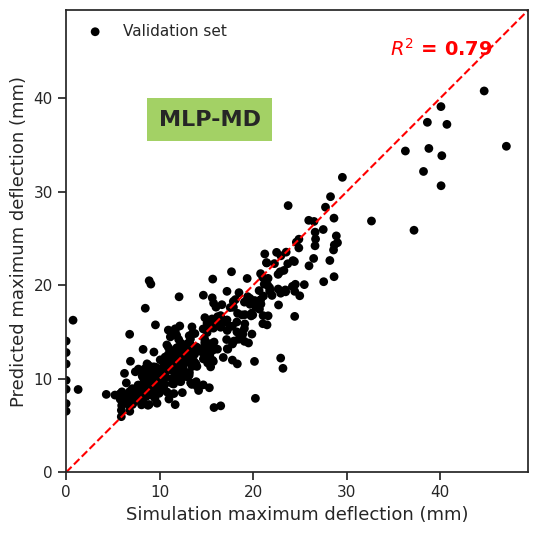

In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from keras.models import Sequential
from keras.layers import Dense, Dropout
from sklearn.metrics import r2_score, mean_absolute_error
import matplotlib.pyplot as plt
import seaborn as sns

# =====================================================================
# 1. INITIALIZE MASTER TRACKING ARRAYS
# =====================================================================
md_fold_r2_scores = []
md_fold_mae_scores = []

# Global arrays to gather ALL validation predictions across all 5 folds
all_true_raw_md = []
all_pred_raw_md = []

print("=== Starting 5-Fold Cross-Validation & Visual Tracking for MD Model ===")

# =====================================================================
# 2. THE MULTI-LAYER PERCEPTRON CROSS-VALIDATION LOOP
# =====================================================================
for fold, (train_idx, test_idx) in enumerate(kf.split(X_scale), 1):
    print(f"\n--- Training Fold {fold}/5 ---")

    # Slice the data dynamically for this specific fold iteration
    X_train_f, X_test_f = X_scale[train_idx], X_scale[test_idx]
    y_train_f, y_test_f = y_scale_md[train_idx], y_scale_md[test_idx]

    # Reset backend weight arrays before building a fresh model
    tf.keras.backend.clear_session()
    fold_model_md = Sequential([
        Dense(64, activation='relu', input_dim=23), # Changed input_dim to 23 to match your input variables
        Dropout(0.2),
        Dense(64, activation='relu'),
        Dropout(0.2),
        Dense(64, activation='relu'),
        Dropout(0.2),
        Dense(1, activation='linear')
    ])

    # Compile with optimized hyperparameters
    optimizer_md = keras.optimizers.Adam(learning_rate=0.0004, weight_decay=0.0005, clipnorm=1.0)
    fold_model_md.compile(optimizer=optimizer_md, loss='mse', metrics=['mae'])

    # Train the network on this fold's configuration
    fold_model_md.fit(
        X_train_f, y_train_f,
        batch_size=32,
        epochs=175,
        validation_data=(X_test_f, y_test_f),
        verbose=0  # Keeps the console clean during execution
    )

    # Generate scaled predictions
    predictions_scaled = fold_model_md.predict(X_test_f).flatten()

    # Reconstruct shape to safely inverse-transform back to physical units
    # scaler_Y expects 3 columns: [MD, RC, SEA]. MD is at index 0.
    dummy_true = np.zeros((len(y_test_f), 3))
    dummy_pred = np.zeros((len(y_test_f), 3))

    dummy_true[:, 0] = y_test_f
    dummy_pred[:, 0] = predictions_scaled

    true_raw_md = scaler_Y.inverse_transform(dummy_true)[:, 0]
    pred_raw_md = scaler_Y.inverse_transform(dummy_pred)[:, 0]

    # Calculate both evaluation metrics for this fold iteration
    fold_r2 = r2_score(true_raw_md, pred_raw_md)
    fold_mae = mean_absolute_error(true_raw_md, pred_raw_md)

    # Save tracking indicators
    md_fold_r2_scores.append(fold_r2)
    md_fold_mae_scores.append(fold_mae)

    # Extend master tracking lists with unscaled data from this fold iteration
    all_true_raw_md.extend(true_raw_md)
    all_pred_raw_md.extend(pred_raw_md)

    print(f"Fold {fold} Complete. Unscaled R² Score: {fold_r2:.4f} | MAE: {fold_mae:.2f}")

# Convert global list items into structured numpy evaluation vectors
all_true_raw_md = np.array(all_true_raw_md)
all_pred_raw_md = np.array(all_pred_raw_md)

# Compute final overall combined metrics
final_mean_r2_md = np.mean(md_fold_r2_scores)
final_mean_mae_md = np.mean(md_fold_mae_scores)

print("\n==============================================")
print("      FINAL AGGREGATED 5-FOLD MD METRICS      ")
print("==============================================")
print(f"FINAL MEAN R² SCORE : {final_mean_r2_md:.4f}")
print(f"FINAL MEAN MAE VALUE: {final_mean_mae_md:.2f} mm")
print("==============================================")


# =====================================================================
# 3. VISUALIZATION GENERATION SUBROUTINE
# =====================================================================
sns.set_theme(style="ticks")
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 12

plt.figure(figsize=(6, 5.5))

# Plot full out-of-fold combined predictions matching dark solid dot elements
plt.scatter(all_true_raw_md, all_pred_raw_md, color='black', edgecolor='none', s=40, label='Validation set')

# Configure perfectly symmetrical square limits dynamically
min_val = min(min(all_true_raw_md), min(all_pred_raw_md)) * 0.95
max_val = max(max(all_true_raw_md), max(all_pred_raw_md)) * 1.05

# Perfect alignment red dashed vector trajectory line (y = x)
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=1.5)

# Labeling matching paper physical metric names for Maximum Deflection (MD)
plt.xlabel('Simulation maximum deflection (mm)', fontsize=13)
plt.ylabel('Predicted maximum deflection (mm)', fontsize=13)
plt.xlim(min_val, max_val)
plt.ylim(min_val, max_val)

# Add text layers using green bounding box patch background styles
plt.text(0.70, 0.90, f'$R^2$ = {final_mean_r2_md:.2f}', transform=plt.gca().transAxes, color='red', fontsize=14, fontweight='bold')
plt.text(0.20, 0.75, 'MLP-MD', transform=plt.gca().transAxes, fontsize=16, fontweight='bold',
         bbox=dict(facecolor='#8cc63f', alpha=0.8, edgecolor='none', pad=8))

plt.legend(loc='upper left', frameon=False)
plt.gca().set_aspect('equal', adjustable='box')
plt.tight_layout()
plt.show()

=== Starting 5-Fold Cross-Validation & Visual Tracking for RC Model ===

--- Training Fold 1/5 ---


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
Fold 1 Complete. Unscaled R² Score: 0.5488 | MAE: 20.95

--- Training Fold 2/5 ---


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
Fold 2 Complete. Unscaled R² Score: 0.4053 | MAE: 19.13

--- Training Fold 3/5 ---


...

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
Fold 3 Complete. Unscaled R² Score: 0.5803 | MAE: 19.22

--- Training Fold 4/5 ---


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
Fold 4 Complete. Unscaled R² Score: 0.5683 | MAE: 17.75

--- Training Fold 5/5 ---


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
Fold 5 Complete. Unscaled R² Score: 0.5804 | MAE: 19.75

      FINAL AGGREGATED 5-FOLD RC METRICS      
FINAL MEAN R² SCORE : 0.5366
FINAL MEAN MAE VALUE: 19.36 KN


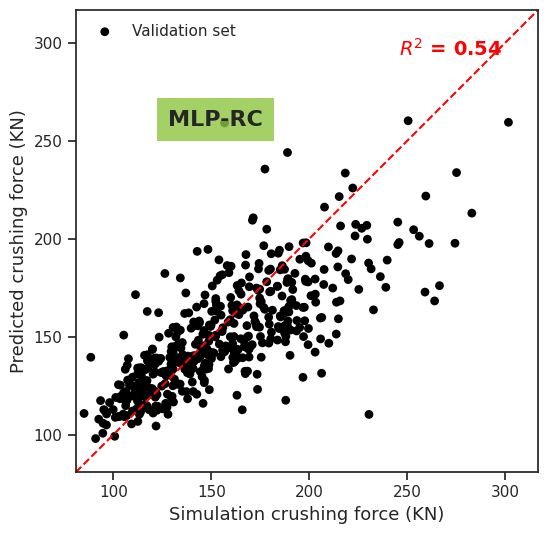

In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from keras.models import Sequential
from keras.layers import Dense, Dropout
from sklearn.metrics import r2_score, mean_absolute_error
import matplotlib.pyplot as plt
import seaborn as sns

# =====================================================================
# 1. INITIALIZE MASTER TRACKING ARRAYS
# =====================================================================
rc_fold_r2_scores = []
rc_fold_mae_scores = []

# Global arrays to gather ALL validation predictions across all 5 folds
all_true_raw_rc = []
all_pred_raw_rc = []

print("=== Starting 5-Fold Cross-Validation & Visual Tracking for RC Model ===")

# =====================================================================
# 2. THE MULTI-LAYER PERCEPTRON CROSS-VALIDATION LOOP
# =====================================================================
for fold, (train_idx, test_idx) in enumerate(kf.split(X_scale), 1):
    print(f"\n--- Training Fold {fold}/5 ---")

    # Slice the data dynamically for this specific fold iteration (index 1 for RC)
    X_train_f, X_test_f = X_scale[train_idx], X_scale[test_idx]
    y_train_f, y_test_f = y_scale_rc[train_idx], y_scale_rc[test_idx]

    # Reset backend weight arrays before building a fresh model
    tf.keras.backend.clear_session()
    fold_model_rc = Sequential([
        Dense(64, activation='relu', input_dim=23),
        Dropout(0.2),
        Dense(64, activation='relu'),
        Dropout(0.2),
        Dense(64, activation='relu'),
        Dropout(0.2),
        Dense(1, activation='linear')
    ])

    # Compile with optimized hyperparameters
    optimizer_rc = keras.optimizers.Adam(learning_rate=0.0004, weight_decay=0.0005, clipnorm=1.0)
    fold_model_rc.compile(optimizer=optimizer_rc, loss='mse', metrics=['mae'])

    # Train the network on this fold's configuration
    fold_model_rc.fit(
        X_train_f, y_train_f,
        batch_size=32,
        epochs=175,
        validation_data=(X_test_f, y_test_f),
        verbose=0  # Keeps the console clean during execution
    )

    # Generate scaled predictions
    predictions_scaled = fold_model_rc.predict(X_test_f).flatten()

    # Reconstruct shape to safely inverse-transform back to physical units
    # scaler_Y expects 3 columns: [MD, RC, SEA]. RC is at index 1.
    dummy_true = np.zeros((len(y_test_f), 3))
    dummy_pred = np.zeros((len(y_test_f), 3))

    dummy_true[:, 1] = y_test_f
    dummy_pred[:, 1] = predictions_scaled

    true_raw_rc = scaler_Y.inverse_transform(dummy_true)[:, 1]
    pred_raw_rc = scaler_Y.inverse_transform(dummy_pred)[:, 1]

    # Calculate both evaluation metrics for this fold iteration
    fold_r2 = r2_score(true_raw_rc, pred_raw_rc)
    fold_mae = mean_absolute_error(true_raw_rc, pred_raw_rc)

    # Save tracking indicators
    rc_fold_r2_scores.append(fold_r2)
    rc_fold_mae_scores.append(fold_mae)

    # Extend master tracking lists with unscaled data from this fold iteration
    all_true_raw_rc.extend(true_raw_rc)
    all_pred_raw_rc.extend(pred_raw_rc)

    print(f"Fold {fold} Complete. Unscaled R² Score: {fold_r2:.4f} | MAE: {fold_mae:.2f}")

# Convert global list items into structured numpy evaluation vectors
all_true_raw_rc = np.array(all_true_raw_rc)
all_pred_raw_rc = np.array(all_pred_raw_rc)

# Compute final overall combined metrics
final_mean_r2_rc = np.mean(rc_fold_r2_scores)
final_mean_mae_rc = np.mean(rc_fold_mae_scores)

print("\n==============================================")
print("      FINAL AGGREGATED 5-FOLD RC METRICS      ")
print("==============================================")
print(f"FINAL MEAN R² SCORE : {final_mean_r2_rc:.4f}")
print(f"FINAL MEAN MAE VALUE: {final_mean_mae_rc:.2f} KN")
print("==============================================")


# =====================================================================
# 3. VISUALIZATION GENERATION SUBROUTINE
# =====================================================================
sns.set_theme(style="ticks")
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 12

plt.figure(figsize=(6, 5.5))

# Plot full out-of-fold combined predictions matching dark solid dot elements
plt.scatter(all_true_raw_rc, all_pred_raw_rc, color='black', edgecolor='none', s=40, label='Validation set')

# Configure perfectly symmetrical square limits dynamically
min_val = min(min(all_true_raw_rc), min(all_pred_raw_rc)) * 0.95
max_val = max(max(all_true_raw_rc), max(all_pred_raw_rc)) * 1.05

# Perfect alignment red dashed vector trajectory line (y = x)
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=1.5)

# Labeling matching paper physical metric names for Crush Resistance / Force (RC)
plt.xlabel('Simulation crushing force (KN)', fontsize=13)
plt.ylabel('Predicted crushing force (KN)', fontsize=13)
plt.xlim(min_val, max_val)
plt.ylim(min_val, max_val)

# Add text layers using green bounding box patch background styles
plt.text(0.70, 0.90, f'$R^2$ = {final_mean_r2_rc:.2f}', transform=plt.gca().transAxes, color='red', fontsize=14, fontweight='bold')
plt.text(0.20, 0.75, 'MLP-RC', transform=plt.gca().transAxes, fontsize=16, fontweight='bold',
         bbox=dict(facecolor='#8cc63f', alpha=0.8, edgecolor='none', pad=8))

plt.legend(loc='upper left', frameon=False)
plt.gca().set_aspect('equal', adjustable='box')
plt.tight_layout()
plt.show()

=== Starting 5-Fold Cross-Validation & Visual Tracking for SEA Model ===

--- Training Fold 1/5 ---


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
Fold 1 Complete. Unscaled R² Score: 0.8258 | MAE: 24.48

--- Training Fold 2/5 ---


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
Fold 2 Complete. Unscaled R² Score: 0.7049 | MAE: 22.82

--- Training Fold 3/5 ---


...

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
Fold 3 Complete. Unscaled R² Score: 0.8182 | MAE: 26.06

--- Training Fold 4/5 ---


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
Fold 4 Complete. Unscaled R² Score: 0.6866 | MAE: 28.01

--- Training Fold 5/5 ---


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
Fold 5 Complete. Unscaled R² Score: 0.8074 | MAE: 24.58

      FINAL AGGREGATED 5-FOLD SEA METRICS      
FINAL MEAN R² SCORE : 0.7686
FINAL MEAN MAE VALUE: 25.19 J/Kg


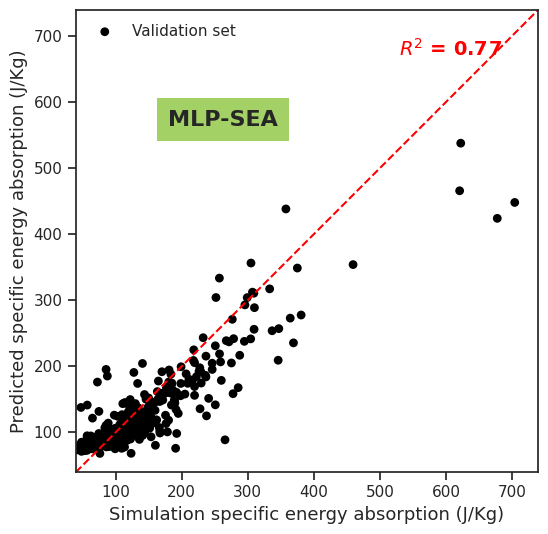

In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from keras.models import Sequential
from keras.layers import Dense, Dropout
from sklearn.metrics import r2_score, mean_absolute_error
import matplotlib.pyplot as plt
import seaborn as sns

# =====================================================================
# 1. INITIALIZE MASTER TRACKING ARRAYS
# =====================================================================
sea_fold_r2_scores = []
sea_fold_mae_scores = []

# Global arrays to gather ALL validation predictions across all 5 folds
all_true_raw_sea = []
all_pred_raw_sea = []

print("=== Starting 5-Fold Cross-Validation & Visual Tracking for SEA Model ===")

# =====================================================================
# 2. THE MULTI-LAYER PERCEPTRON CROSS-VALIDATION LOOP
# =====================================================================
for fold, (train_idx, test_idx) in enumerate(kf.split(X_scale), 1):
    print(f"\n--- Training Fold {fold}/5 ---")

    # Slice the data dynamically for this specific fold iteration (index 2 for SEA)
    X_train_f, X_test_f = X_scale[train_idx], X_scale[test_idx]
    y_train_f, y_test_f = y_scale_sea[train_idx], y_scale_sea[test_idx]

    # Reset backend weight arrays before building a fresh model
    tf.keras.backend.clear_session()
    fold_model_sea = Sequential([
        Dense(64, activation='relu', input_dim=23),
        Dropout(0.2),
        Dense(64, activation='relu'),
        Dropout(0.2),
        Dense(64, activation='relu'),
        Dropout(0.2),
        Dense(1, activation='linear')
    ])

    # Compile with optimized hyperparameters
    optimizer_sea = keras.optimizers.Adam(learning_rate=0.0004, weight_decay=0.0005, clipnorm=1.0)
    fold_model_sea.compile(optimizer=optimizer_sea, loss='mse', metrics=['mae'])

    # Train the network on this fold's configuration
    fold_model_sea.fit(
        X_train_f, y_train_f,
        batch_size=32,
        epochs=175,
        validation_data=(X_test_f, y_test_f),
        verbose=0  # Keeps the console clean during execution
    )

    # Generate scaled predictions
    predictions_scaled = fold_model_sea.predict(X_test_f).flatten()

    # Reconstruct shape to safely inverse-transform back to physical units
    # scaler_Y expects 3 columns: [MD, RC, SEA]. SEA is at index 2.
    dummy_true = np.zeros((len(y_test_f), 3))
    dummy_pred = np.zeros((len(y_test_f), 3))

    dummy_true[:, 2] = y_test_f
    dummy_pred[:, 2] = predictions_scaled

    true_raw_sea = scaler_Y.inverse_transform(dummy_true)[:, 2]
    pred_raw_sea = scaler_Y.inverse_transform(dummy_pred)[:, 2]

    # Calculate both evaluation metrics for this fold iteration
    fold_r2 = r2_score(true_raw_sea, pred_raw_sea)
    fold_mae = mean_absolute_error(true_raw_sea, pred_raw_sea)

    # Save tracking indicators
    sea_fold_r2_scores.append(fold_r2)
    sea_fold_mae_scores.append(fold_mae)

    # Extend master tracking lists with unscaled data from this fold iteration
    all_true_raw_sea.extend(true_raw_sea)
    all_pred_raw_sea.extend(pred_raw_sea)

    print(f"Fold {fold} Complete. Unscaled R² Score: {fold_r2:.4f} | MAE: {fold_mae:.2f}")

# Convert global list items into structured numpy evaluation vectors
all_true_raw_sea = np.array(all_true_raw_sea)
all_pred_raw_sea = np.array(all_pred_raw_sea)

# Compute final overall combined metrics
final_mean_r2_sea = np.mean(sea_fold_r2_scores)
final_mean_mae_sea = np.mean(sea_fold_mae_scores)

print("\n==============================================")
print("      FINAL AGGREGATED 5-FOLD SEA METRICS      ")
print("==============================================")
print(f"FINAL MEAN R² SCORE : {final_mean_r2_sea:.4f}")
print(f"FINAL MEAN MAE VALUE: {final_mean_mae_sea:.2f} J/Kg")
print("==============================================")


# =====================================================================
# 3. VISUALIZATION GENERATION SUBROUTINE
# =====================================================================
sns.set_theme(style="ticks")
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 12

plt.figure(figsize=(6, 5.5))

# Plot full out-of-fold combined predictions matching dark solid dot elements
plt.scatter(all_true_raw_sea, all_pred_raw_sea, color='black', edgecolor='none', s=40, label='Validation set')

# Configure perfectly symmetrical square limits dynamically
min_val = min(min(all_true_raw_sea), min(all_pred_raw_sea)) * 0.95
max_val = max(max(all_true_raw_sea), max(all_pred_raw_sea)) * 1.05

# Perfect alignment red dashed vector trajectory line (y = x)
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=1.5)

# Labeling matching paper physical metric names for Specific Energy Absorption (SEA)
plt.xlabel('Simulation specific energy absorption (J/Kg)', fontsize=13)
plt.ylabel('Predicted specific energy absorption (J/Kg)', fontsize=13)
plt.xlim(min_val, max_val)
plt.ylim(min_val, max_val)

# Add text layers using green bounding box patch background styles
plt.text(0.70, 0.90, f'$R^2$ = {final_mean_r2_sea:.2f}', transform=plt.gca().transAxes, color='red', fontsize=14, fontweight='bold')
plt.text(0.20, 0.75, 'MLP-SEA', transform=plt.gca().transAxes, fontsize=16, fontweight='bold',
         bbox=dict(facecolor='#8cc63f', alpha=0.8, edgecolor='none', pad=8))

plt.legend(loc='upper left', frameon=False)
plt.gca().set_aspect('equal', adjustable='box')
plt.tight_layout()
plt.show()